# ДЗ 4. Full Fine-Tuning и LoRA

Датасет — **SQuAD 2.0**. Нужно отвечать по контексту или писать `UNANSWERABLE`, если ответа нет.

Для запуска установить `requirements.txt`. Обучение включается через `RUN_TRAINING = True`; GPU выбирается через `CUDA_VISIBLE_DEVICES=0` при запуске Jupyter. При `False` используются сохранённые результаты.

In [1]:
import gc
import json
import random
import re
import time
import hashlib
import string
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from IPython.display import Markdown, display
from peft import LoraConfig, get_peft_model
from transformers import (
    AutoModelForCausalLM, AutoTokenizer, DataCollatorForSeq2Seq,
    GenerationConfig, Trainer, TrainingArguments, set_seed,
)

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
MODEL_REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"
ROOT = Path.cwd() if Path("finetuning_hw.ipynb").exists() else Path.cwd() / "hw4"
DATA = ROOT / "data"
OUTPUT = ROOT / "outputs"
RUN_TRAINING = False
DATASET_REVISION = "3ffb306f725f7d2ce8394bc1873b24868140c412"
set_seed(SEED)
pd.set_option("display.max_colwidth", 120)

/private/tmp/hw4-check-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Данные

Вообще сначала думал брать датасет с математическими задачками, но чет там квен портился, поэтому выбрал я SQuAD 2.0: он содержит вопросы по текстам Wikipedia, в том числе без ответа. На нём можно проверить, научится ли модель отказываться вместо выдумывания ответа.

Из исходных 130 319 обучающих примеров взяты 10 000 для train и 400 для validation. Для validation выделены отдельные 40 статей. Test - 800 примеров из официального validation. В каждой части поровну вопросов с ответом и без него, контексты между частями не пересекаются. Для всех моделей используются одинаковые выборки.

Примеры train/validation длиннее 1024 токенов исключены, остальные не обрезались. Ниже(через ячейку) два примера.

In [2]:
SYSTEM_PROMPT = 'Answer the question using only the context. Return only the shortest answer copied from the context, with no explanation. If the context does not contain the answer, reply exactly UNANSWERABLE.'
tokenizer_source = DATA / 'tokenizer' if (DATA / 'tokenizer').exists() else MODEL_NAME
tokenizer = AutoTokenizer.from_pretrained(tokenizer_source, revision=MODEL_REVISION, padding_side='right')

if not (DATA / "metadata.json").exists():
    DATA.mkdir(parents=True, exist_ok=True)
    source = load_dataset('rajpurkar/squad_v2', revision=DATASET_REVISION)
    rng = random.Random(SEED)
    titles = sorted(set(source['train']['title']))
    rng.shuffle(titles)
    validation_titles = set(titles[:40])


    def example(row):
        answers = row['answers']['text']
        return dict(id=row['id'], title=row['title'], context=row['context'], question=row['question'],
                    answers=answers, answer=answers[0] if answers else 'UNANSWERABLE',
                    messages=[dict(role='system', content=SYSTEM_PROMPT),
                              dict(role='user', content=f"Context:\n{row['context']}\n\nQuestion: {row['question']}")])


    def balanced(rows, count, seed, max_tokens=None):
        generator = random.Random(seed)
        selected = []
        for answerable in [True, False]:
            candidates = [row for row in rows if bool(row['answers']['text']) == answerable]
            generator.shuffle(candidates)
            group = []
            for row in candidates:
                item = example(row)
                if max_tokens is not None:
                    messages = item['messages'] + [dict(role='assistant', content=item['answer'])]
                    if len(tokenizer.apply_chat_template(messages, tokenize=True)) > max_tokens:
                        continue
                group.append(item)
                if len(group) == count // 2:
                    break
            assert len(group) == count // 2
            selected.extend(group)
        generator.shuffle(selected)
        return selected


    train_pool = [row for row in source['train'] if row['title'] not in validation_titles]
    validation_pool = [row for row in source['train'] if row['title'] in validation_titles]
    splits = {
        'train': balanced(train_pool, 10000, SEED, 1024),
        'validation': balanced(validation_pool, 400, SEED + 1, 1024),
        'test': balanced(list(source['validation']), 800, SEED + 2),
    }
    manual = []
    for answerable in [True, False]:
        candidates = [row for row in splits['test'] if bool(row['answers']) == answerable]
        manual.extend(random.Random(SEED + 3).sample(candidates, 5))
    contexts = [{row['context'] for row in rows} for rows in splits.values()]
    assert all(not contexts[i] & contexts[j] for i, j in [(0, 1), (0, 2), (1, 2)])
    metadata = dict(dataset='rajpurkar/squad_v2', dataset_revision=DATASET_REVISION, seed=SEED,
                    original_sizes={name: len(rows) for name, rows in source.items()},
                    validation_titles=sorted(validation_titles), manual_ids=[row['id'] for row in manual],
                    system_prompt=SYSTEM_PROMPT, splits={})
    for name, rows in splits.items():
        path = DATA / f'{name}.jsonl'
        path.write_text(''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in rows))
        lengths = sorted(len(tokenizer.apply_chat_template(row['messages'] + [dict(role='assistant', content=row['answer'])], tokenize=True)) for row in rows)
        metadata['splits'][name] = dict(count=len(rows), answerable=sum(bool(row['answers']) for row in rows),
                                      max_tokens=lengths[-1], median_tokens=lengths[len(lengths)//2],
                                      sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    (DATA / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2))


def read_jsonl(path):
    return [json.loads(line) for line in path.read_text().splitlines() if line]

train_rows = read_jsonl(DATA / "train.jsonl")
validation_rows = read_jsonl(DATA / "validation.jsonl")
test_rows = read_jsonl(DATA / "test.jsonl")
metadata = json.loads((DATA / "metadata.json").read_text())
contexts = [{row["context"] for row in rows} for rows in [train_rows, validation_rows, test_rows]]
assert all(not contexts[i] & contexts[j] for i, j in [(0, 1), (0, 2), (1, 2)])
for name, info in metadata["splits"].items():
    assert hashlib.sha256((DATA / f"{name}.jsonl").read_bytes()).hexdigest() == info["sha256"]
display(pd.DataFrame(metadata["splits"]).T.drop(columns="sha256"))

,count,answerable,max_tokens,median_tokens
train,10000,5000,812,224
validation,400,200,515,223
test,800,400,883,226


In [3]:
for answerable in [True, False]:
    row = next(row for row in train_rows if bool(row["answers"]) == answerable)
    print("Context:", row["context"])
    print("Question:", row["question"])
    print("Answer:", row["answer"], "\n")

Context: The focus on the Hellenistic period over the course of the 19th century by scholars and historians has led to an issue common to the study of historical periods; historians see the period of focus as a mirror of the period in which they are living. Many 19th century scholars contended that the Hellenistic period represented a cultural decline from the brilliance of classical Greece. Though this comparison is now seen as unfair and meaningless, it has been noted that even commentators of the time saw the end of a cultural era which could not be matched again. This may be inextricably linked with the nature of government. It has been noted by Herodotus that after the establishment of the Athenian democracy:
Question: The viewpoint that the Hellenistic period represented a decline in culture was proven to be meaningless and what?
Answer: unfair 

Context: In 1816, the United Kingdom annexed the islands, ruling them from the Cape Colony in South Africa. This is reported to have pr

## Подготовка к обучению

Используется chat template Qwen. Loss считается только по ответу и EOS.

Full FT: веса и AdamW в FP32, вычисления с BF16 autocast. LoRA: основная модель в BF16, адаптеры в FP32. При генерации основная модель всегда в BF16.

In [4]:
def encode_example(row):
    prompt = tokenizer.apply_chat_template(row["messages"], tokenize=True, add_generation_prompt=True)
    tokens = tokenizer.apply_chat_template(
        row["messages"] + [dict(role="assistant", content=row["answer"])], tokenize=True,
    )
    assert tokens[:len(prompt)] == prompt
    tokens = tokens[:tokens.index(tokenizer.eos_token_id, len(prompt)) + 1]
    assert len(tokens) <= 1024
    return dict(input_ids=tokens, attention_mask=[1] * len(tokens),
                labels=[-100] * len(prompt) + tokens[len(prompt):])


train_dataset = Dataset.from_list([encode_example(row) for row in train_rows])
validation_dataset = Dataset.from_list([encode_example(row) for row in validation_rows])
display(pd.DataFrame({
    "train_tokens": pd.Series([len(row["input_ids"]) for row in train_dataset]).describe(),
    "validation_tokens": pd.Series([len(row["input_ids"]) for row in validation_dataset]).describe(),
}))

,train_tokens,validation_tokens
count,10000.000000,400.000000
mean,236.920100,238.545000
std,69.940807,59.905171
min,95.000000,104.000000
25%,192.750000,197.000000
50%,223.000000,222.000000
75%,268.000000,268.000000
max,811.000000,514.000000


## Настройки

In [5]:
LORA = dict(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "v_proj"])
EXPERIMENTS = {
    "base": dict(method="base", learning_rate=0.0),
    "full_ft": dict(method="full", learning_rate=2e-5),
    "lora": dict(method="lora", learning_rate=2e-4, **LORA),
    "lora_r32": dict(method="lora", learning_rate=2e-4, **{**LORA, "r": 32}),
    "lora_alpha64": dict(method="lora", learning_rate=2e-4, **{**LORA, "lora_alpha": 64}),
    "lora_dropout0": dict(method="lora", learning_rate=2e-4, **{**LORA, "lora_dropout": 0.0}),
    "lora_all": dict(method="lora", learning_rate=2e-4, **{**LORA, "target_modules": [
        "q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj",
    ]}),
}
TRAINING = dict(
    num_train_epochs=1, per_device_train_batch_size=8, per_device_eval_batch_size=4,
    gradient_accumulation_steps=4, lr_scheduler_type="cosine", warmup_ratio=0.05,
    weight_decay=0.01, max_grad_norm=1.0, gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False}, bf16=True, tf32=True,
    optim="adamw_torch_fused", logging_steps=10, eval_strategy="no", save_strategy="no",
    report_to="none", seed=SEED, data_seed=SEED, skip_memory_metrics=True,
)

PILOTS = {
    "full_low": dict(method="full", learning_rate=5e-6),
    "full_high": dict(method="full", learning_rate=2e-5),
    "lora_low": dict(method="lora", learning_rate=5e-5, **LORA),
    "lora_high": dict(method="lora", learning_rate=2e-4, **LORA),
}
for name in list(EXPERIMENTS)[3:]:
    assert sum(EXPERIMENTS[name][key] != EXPERIMENTS["lora"][key] for key in LORA) == 1

## Метрики

**EM** проверяет точное совпадение после нормализации SQuAD, а **F1** учитывает частичное совпадение токенов. Поэтому первая метрика строже, вторая позволяет оценить неполные ответы. При нескольких эталонах берётся лучший результат. Обе метрики оценивают задачу дообучения — ответы по контексту.

`UNANSWERABLE` переводится в пустой ответ. Дополнительно качество показано отдельно для вопросов с ответом и без него. Все модели используют greedy decoding с лимитом 64 новых токена. Метрики в процентах: больше — лучше.

In [6]:
def normalize_answer(text):
    text = text.lower().translate(str.maketrans("", "", string.punctuation))
    return " ".join(re.sub(r"\b(a|an|the)\b", " ", text).split())


def answer_scores(prediction, answers):
    prediction = "" if normalize_answer(prediction) == "unanswerable" else prediction
    predicted = normalize_answer(prediction)
    references = [normalize_answer(answer) for answer in answers if normalize_answer(answer)] or [""]
    exact, f1 = 0.0, 0.0
    for reference in references:
        exact = max(exact, float(predicted == reference))
        p, r = predicted.split(), reference.split()
        overlap = sum((Counter(p) & Counter(r)).values())
        score = float(p == r) if not p or not r else 2 * overlap / (len(p) + len(r))
        f1 = max(f1, score)
    return dict(exact=exact, f1=f1, abstained=not predicted)


@torch.inference_mode()
def evaluate(model, rows, batch_size=16):
    model.eval()
    model.config.use_cache = True
    tokenizer.padding_side = "left"
    prompts = [tokenizer.apply_chat_template(row["messages"], tokenize=False, add_generation_prompt=True)
               for row in rows]
    order = sorted(range(len(rows)), key=lambda i: len(prompts[i]))
    predictions = [None] * len(rows)
    generation = GenerationConfig(do_sample=False, num_beams=1, max_new_tokens=64,
                                  eos_token_id=tokenizer.eos_token_id,
                                  pad_token_id=tokenizer.pad_token_id, use_cache=True)
    for start in range(0, len(order), batch_size):
        indices = order[start:start + batch_size]
        inputs = tokenizer([prompts[i] for i in indices], padding=True, add_special_tokens=False,
                           return_tensors="pt").to(model.device)
        tokens = model.generate(**inputs, generation_config=generation)[:, inputs.input_ids.shape[1]:]
        for i, text, token_ids in zip(indices, tokenizer.batch_decode(tokens, skip_special_tokens=True), tokens.tolist()):
            predictions[i] = dict(id=rows[i]["id"], prediction=text.strip(),
                                  answerable=bool(rows[i]["answers"]),
                                  **answer_scores(text, rows[i]["answers"]),
                                  hit_token_limit=tokenizer.eos_token_id not in token_ids and len(token_ids) == 64)
        if start % 160 == 0:
            print(f"Evaluated {min(start + batch_size, len(order))}/{len(order)}", flush=True)
    tokenizer.padding_side = "right"
    return pd.DataFrame(predictions)


def summarize(predictions):
    return dict(exact_match=100 * predictions["exact"].mean(), f1=100 * predictions["f1"].mean(),
                answerable_f1=100 * predictions.loc[predictions.answerable, "f1"].mean(),
                no_answer_accuracy=100 * predictions.loc[~predictions.answerable, "exact"].mean(),
                abstention_rate=100 * predictions["abstained"].mean(),
                hit_token_limit=int(predictions["hit_token_limit"].sum()), n=len(predictions))

assert answer_scores("The red fox!", ["red fox"])["exact"] == 1
assert answer_scores("red", ["red fox"])["f1"] == 2 / 3
assert answer_scores("UNANSWERABLE", [])["exact"] == 1
assert answer_scores("fox", [])["f1"] == 0
assert answer_scores("blue", ["red", "blue"])["exact"] == 1

## Обучение и оценка

Время измеряется только для обучения, без загрузки и сохранения весов. Память измеряется через PyTorch: allocated — тензоры, reserved — память аллокатора. Для исходной модели затраты на обучение равны нулю.

In [7]:
def run_experiment(name, config, rows, pilot=False):
    set_seed(SEED)
    folder = OUTPUT / ("pilots" if pilot else "") / name
    training = {**TRAINING, **({"max_steps": 40} if pilot else {})}
    folder.mkdir(parents=True, exist_ok=True)
    dtype = torch.float32 if config["method"] == "full" else torch.bfloat16
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, revision=MODEL_REVISION, dtype=dtype, attn_implementation="sdpa",
    ).to("cuda")
    if config["method"] == "lora":
        model = get_peft_model(model, LoraConfig(task_type="CAUSAL_LM", bias="none",
                                               **{key: config[key] for key in LORA}))
    if config["method"] == "base":
        model.requires_grad_(False)
    model.config.use_cache = False
    result = dict(name=name, **config,
                  total_params=sum(p.numel() for p in model.parameters()),
                  trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad),
                  training_seconds=0.0, train_peak_allocated_gib=0.0, train_peak_reserved_gib=0.0)
    (folder / "config.json").write_text(json.dumps(dict(
        experiment=config, training=training, model_revision=MODEL_REVISION,
        dataset_revision=DATASET_REVISION, evaluation_split="validation" if pilot else "test",
        gpu=torch.cuda.get_device_name(), torch_version=torch.__version__,
        trainable_dtypes=sorted({str(p.dtype) for p in model.parameters() if p.requires_grad}),
    ), indent=2))
    if config["method"] != "base":
        assert all(p.dtype == torch.float32 for p in model.parameters() if p.requires_grad)
        trainer = Trainer(
            model=model,
            args=TrainingArguments(output_dir=str(folder), learning_rate=config["learning_rate"], **training),
            train_dataset=train_dataset.select(range(2000)) if pilot else train_dataset, eval_dataset=validation_dataset, processing_class=tokenizer,
            data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, pad_to_multiple_of=8, label_pad_token_id=-100),
        )
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        started = time.perf_counter()
        trainer.train()
        torch.cuda.synchronize()
        result.update(training_seconds=time.perf_counter() - started,
                      train_peak_allocated_gib=torch.cuda.max_memory_allocated() / 2**30,
                      train_peak_reserved_gib=torch.cuda.max_memory_reserved() / 2**30,
                      steps=trainer.state.global_step)
        result["optimizer_state_dtype"] = str(next(iter(trainer.optimizer.state.values()))["exp_avg"].dtype)
        result["validation_loss"] = trainer.evaluate()["eval_loss"]
        (folder / "history.json").write_text(json.dumps(trainer.state.log_history, indent=2))
        if not pilot:
            trainer.save_model(str(folder / "model"))
            tokenizer.save_pretrained(folder / "model")
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
    if config["method"] == "full":
        model.to(torch.bfloat16)
    torch.cuda.synchronize()
    started = time.perf_counter()
    predictions = evaluate(model, rows)
    torch.cuda.synchronize()
    result["evaluation_seconds"] = time.perf_counter() - started
    predictions.to_json(folder / "predictions.json", orient="records", indent=2)
    result.update(summarize(predictions))
    (folder / "metrics.json").write_text(json.dumps(result, indent=2))
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return result

In [8]:
if RUN_TRAINING:
    assert torch.cuda.is_available() and torch.cuda.device_count() == 1
    assert torch.cuda.is_bf16_supported()
    run_experiment("base", EXPERIMENTS["base"], validation_rows, pilot=True)
    pilot_results = [run_experiment(name, config, validation_rows, pilot=True)
                     for name, config in PILOTS.items()]
    selected = {}
    for method in ["full", "lora"]:
        candidates = [result for result in pilot_results if result["method"] == method]
        best = max(candidates, key=lambda row: (row["f1"], row["exact_match"], -row["learning_rate"]))
        selected[method] = best["learning_rate"]
    (OUTPUT / "selected_lr.json").write_text(json.dumps(selected, indent=2))
if (OUTPUT / "selected_lr.json").exists():
    selected = json.loads((OUTPUT / "selected_lr.json").read_text())
    for config in EXPERIMENTS.values():
        if config["method"] in selected:
            config["learning_rate"] = selected[config["method"]]
pilot_results = [json.loads(path.read_text()) for path in sorted((OUTPUT / "pilots").glob("*/metrics.json"))]
if pilot_results:
    display(pd.DataFrame(pilot_results)[["name", "learning_rate", "exact_match", "f1", "answerable_f1", "no_answer_accuracy"]].round({"learning_rate": 6, "exact_match": 3, "f1": 3, "answerable_f1": 3, "no_answer_accuracy": 3}))
display(pd.DataFrame(EXPERIMENTS).T)
if RUN_TRAINING:
    for name, config in EXPERIMENTS.items():
        print(name, flush=True)
        display(pd.DataFrame([run_experiment(name, config, test_rows)]))
else:
    print("Обучение выключено. Для GPU-запуска установите RUN_TRAINING = True.")

,name,learning_rate,exact_match,f1,answerable_f1,no_answer_accuracy
0,base,0.000000,38.50,45.005,77.009,13.0
1,full_high,0.000020,66.00,70.450,55.399,85.5
2,full_low,0.000005,68.25,71.791,65.582,78.0
3,lora_high,0.000200,64.25,67.971,55.942,80.0
4,lora_low,0.000050,63.00,67.157,59.315,75.0


,method,learning_rate,r,lora_alpha,lora_dropout,target_modules
base,base,0.0,NaN,NaN,NaN,NaN
full_ft,full,0.000005,NaN,NaN,NaN,NaN
lora,lora,0.0002,16,32,0.05,"[q_proj, v_proj]"
lora_r32,lora,0.0002,32,32,0.05,"[q_proj, v_proj]"
lora_alpha64,lora,0.0002,16,64,0.05,"[q_proj, v_proj]"
lora_dropout0,lora,0.0002,16,32,0.0,"[q_proj, v_proj]"
lora_all,lora,0.0002,16,32,0.05,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]"


Обучение выключено. Для GPU-запуска установите RUN_TRAINING = True.


## Результаты

Все модели проверены на одних и тех же 800 вопросах.

In [9]:
result_rows = [json.loads((OUTPUT / name / "metrics.json").read_text())
               for name in EXPERIMENTS if (OUTPUT / name / "metrics.json").exists()]
results = pd.DataFrame(result_rows)
if not results.empty:
    results.to_csv(OUTPUT / "results.csv", index=False)
    comparison = results[["name", "exact_match", "f1", "answerable_f1", "no_answer_accuracy",
                          "trainable_params", "training_seconds", "train_peak_allocated_gib"]].copy()
    comparison["trainable_params"] /= 1e6
    comparison["training_seconds"] /= 60
    comparison.columns = ["model", "EM, %", "F1, %", "HasAns F1, %", "NoAns EM, %",
                          "trainable, M", "train, min", "peak, GiB"]
    display(comparison.round(2))
    display(results[["name", "abstention_rate", "hit_token_limit", "train_peak_reserved_gib"]].round(2))

,model,"EM, %","F1, %","HasAns F1, %","NoAns EM, %","trainable, M","train, min","peak, GiB"
0,base,42.75,46.46,84.16,8.75,0.00,0.00,0.00
1,full_ft,77.62,80.76,75.77,85.75,1543.71,6.40,35.93
2,lora,73.50,76.54,68.84,84.25,2.18,4.92,14.57
3,lora_r32,74.00,76.93,70.61,83.25,4.36,4.90,14.59
4,lora_alpha64,75.75,78.84,72.93,84.75,2.18,4.90,14.57
5,lora_dropout0,74.50,77.48,70.71,84.25,2.18,4.79,14.57
6,lora_all,77.62,80.50,76.01,85.00,18.46,7.63,14.75


,name,abstention_rate,hit_token_limit,train_peak_reserved_gib
0,base,4.75,0,0.00
1,full_ft,51.75,0,56.70
2,lora,55.12,0,33.70
3,lora_r32,53.75,0,33.73
4,lora_alpha64,53.00,0,33.70
5,lora_dropout0,54.37,0,33.68
6,lora_all,51.38,0,34.12


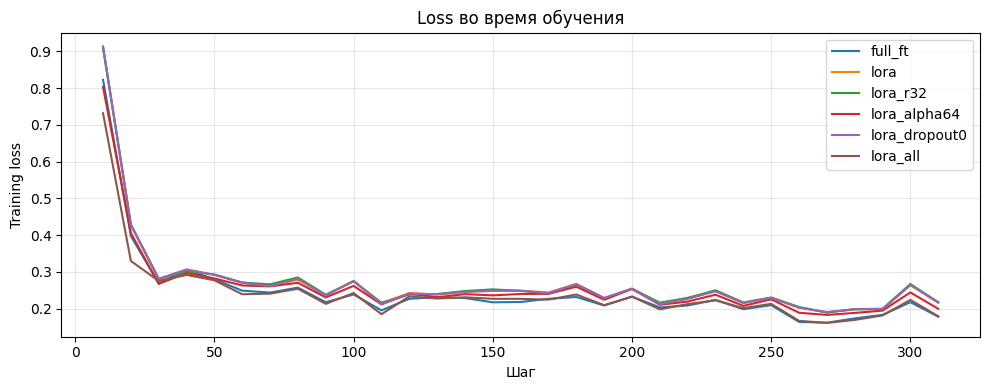

In [10]:
histories = {name: pd.DataFrame(json.loads((OUTPUT / name / "history.json").read_text()))
             for name in EXPERIMENTS if (OUTPUT / name / "history.json").exists()}
if histories:
    fig, ax = plt.subplots(figsize=(10, 4))
    for name, history in histories.items():
        logged = history.dropna(subset=["loss"])
        ax.plot(logged["step"], logged["loss"], label=name)
    ax.set(xlabel="Шаг", ylabel="Training loss", title="Loss во время обучения")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(OUTPUT / "training_loss.png", dpi=160)
    plt.show()

In [11]:
if not results.empty and "lora" in set(results["name"]):
    indexed = results.set_index("name")
    changes = []
    for name, parameter in [("lora_r32", "r"), ("lora_alpha64", "alpha"),
                            ("lora_dropout0", "dropout"), ("lora_all", "target_modules")]:
        if name in indexed.index:
            changes.append(dict(parameter=parameter, experiment=name,
                                em_delta_pp=indexed.loc[name, "exact_match"] - indexed.loc["lora", "exact_match"],
                                f1_delta_pp=indexed.loc[name, "f1"] - indexed.loc["lora", "f1"]))
    display(pd.DataFrame(changes).round(2))

,parameter,experiment,em_delta_pp,f1_delta_pp
0,r,lora_r32,0.50,0.39
1,alpha,lora_alpha64,2.25,2.29
2,dropout,lora_dropout0,1.00,0.94
3,target_modules,lora_all,4.12,3.96


In [12]:
test_by_id = {row["id"]: row for row in test_rows}
manual_predictions = {name: pd.read_json(OUTPUT / name / "predictions.json").set_index("id")
                      for name in ["base", "full_ft", "lora"] if (OUTPUT / name / "predictions.json").exists()}
for example_id in metadata["manual_ids"]:
    row = test_by_id[example_id]
    display(Markdown(f"### {example_id}\n\n{row['context']}\n\n**{row['question']}**\n\nЭталоны: {row['answers'] or ['UNANSWERABLE']}"))
    for name, predictions in manual_predictions.items():
        prediction = predictions.loc[example_id]
        print(f"{name}: {prediction['prediction']} | EM={prediction['exact']:.0f}, F1={prediction['f1']:.3f}")

### 571097baa58dae1900cd6a9a

Paul Revere was descended from Huguenot refugees, as was Henry Laurens, who signed the Articles of Confederation for South Carolina; Jack Jouett, who made the ride from Cuckoo Tavern to warn Thomas Jefferson and others that Tarleton and his men were on their way to arrest him for crimes against the king; Francis Marion, and a number of other leaders of the American Revolution and later statesmen. The last active Huguenot congregation in North America worships in Charleston, South Carolina, at a church that dates to 1844. The Huguenot Society of America maintains Manakin Episcopal Church in Virginia as an historic shrine with occasional services. The Society has chapters in numerous states, with the one in Texas being the largest.

**In what city is the last Huguenot congregation in the US?**

Эталоны: ['Charleston, South Carolina', 'Charleston', 'Charleston, South Carolina']

base: Charleston | EM=1, F1=1.000
full_ft: Charleston, South Carolina | EM=1, F1=1.000
lora: Charleston | EM=1, F1=1.000


### 56de4b074396321400ee2795

In England, the period of Norman architecture immediately succeeds that of the Anglo-Saxon and precedes the Early Gothic. In southern Italy, the Normans incorporated elements of Islamic, Lombard, and Byzantine building techniques into their own, initiating a unique style known as Norman-Arab architecture within the Kingdom of Sicily.

**What place had the Norman Arab architectural style?**

Эталоны: ['Sicily', 'Sicily', 'Kingdom of Sicily']

base: Sicily | EM=1, F1=1.000
full_ft: UNANSWERABLE | EM=0, F1=0.000
lora: UNANSWERABLE | EM=0, F1=0.000


### 5728fd206aef05140015494c

Within the genitourinary and gastrointestinal tracts, commensal flora serve as biological barriers by competing with pathogenic bacteria for food and space and, in some cases, by changing the conditions in their environment, such as pH or available iron. This reduces the probability that pathogens will reach sufficient numbers to cause illness. However, since most antibiotics non-specifically target bacteria and do not affect fungi, oral antibiotics can lead to an "overgrowth" of fungi and cause conditions such as a vaginal candidiasis (a yeast infection). There is good evidence that re-introduction of probiotic flora, such as pure cultures of the lactobacilli normally found in unpasteurized yogurt, helps restore a healthy balance of microbial populations in intestinal infections in children and encouraging preliminary data in studies on bacterial gastroenteritis, inflammatory bowel diseases, urinary tract infection and post-surgical infections.

**What serves as a biological barrier by competing for space and food in the GI tract?**

Эталоны: ['commensal flora', 'commensal flora', 'commensal flora']

base: commensal flora | EM=1, F1=1.000
full_ft: commensal flora | EM=1, F1=1.000
lora: UNANSWERABLE | EM=0, F1=0.000


... (10 outputs left out)

### 5ad0228a77cf76001a686b5a

Many locals and tourists frequent the southern California coast for its popular beaches, and the desert city of Palm Springs is popular for its resort feel and nearby open spaces.

**Which coast is the desert on?**

Эталоны: ['UNANSWERABLE']

base: California | EM=0, F1=0.000
full_ft: UNANSWERABLE | EM=1, F1=1.000
lora: UNANSWERABLE | EM=1, F1=1.000


### 5ad3fd68604f3c001a3ffbe7

Normandy was the site of several important developments in the history of classical music in the 11th century. Fécamp Abbey and Saint-Evroul Abbey were centres of musical production and education. At Fécamp, under two Italian abbots, William of Volpiano and John of Ravenna, the system of denoting notes by letters was developed and taught. It is still the most common form of pitch representation in English- and German-speaking countries today. Also at Fécamp, the staff, around which neumes were oriented, was first developed and taught in the 11th century. Under the German abbot Isembard, La Trinité-du-Mont became a centre of musical composition.

**What developed in Normandy during the 1100s?**

Эталоны: ['UNANSWERABLE']

base: notes by letters | EM=0, F1=0.000
full_ft: UNANSWERABLE | EM=1, F1=1.000
lora: UNANSWERABLE | EM=1, F1=1.000


## Ручная оценка

Заранее выбраны 10 примеров: пять с ответом и пять без. По разметке совпали **5/10 у Base, 7/10 у Full FT и 6/10 у LoRA**. Полные ответы приведены ниже.

✓ — верно по разметке, × — ошибка.

| № | Пример | Base | Full FT | LoRA | Наблюдение |
|---|---|---|---|---|---|
| 1 | Город последней общины гугенотов | ✓ | ✓ | ✓ | Charleston и Charleston, South Carolina входят в эталоны. |
| 2 | Норманно-арабская архитектура | ✓ | × | × | Обе дообученные модели отказываются, хотя Sicily прямо есть в контексте. |
| 3 | Биологический барьер | ✓ | ✓ | × | LoRA пропускает явный ответ commensal flora. |
| 4 | Полномочия неизбранных членов | ✓ | ✓ | ✓ | Все правильно отвечают vote. |
| 5 | Президент Гарварда | ✓ | ✓ | ✓ | Все находят Charles W. Eliot. |
| 6 | Движение по Аристотелю | × | × | × | Все отвечают left alone, не замечая подмену неподвижных объектов движущимися. |
| 7 | Должность Hoesung Lee | × | ✓ | ✓ | В тексте указан председатель IPCC, а вопрос спрашивает про президента. |
| 8 | Работа Филона | × | × | × | Все отвечают Leonardo da Vinci; разметка требует отказа. |
| 9 | Побережье пустыни | × | ✓ | ✓ | Из текста нельзя установить, на каком побережье расположена пустыня. |
| 10 | Музыка в Нормандии | × | ✓ | ✓ | XI век в контексте не совпадает с 1100-ми годами в вопросе. |

Дообучение помогает отказываться, но иногда отказ появляется там, где ответ есть.

## Итоговая таблица

| Модель | EM, % | F1, % | Обучаемые параметры, млн | Время, мин | Пик памяти, GiB |
|---|---:|---:|---:|---:|---:|
| Исходная модель | 42,75 | 46,46 | 0,00 | 0,00 | 0,00 |
| Full FT | 77,62 | 80,76 | 1543,71 | 6,40 | 35,93 |
| Базовый LoRA | 73,50 | 76,54 | 2,18 | 4,92 | 14,57 |
| LoRA: r=32 | 74,00 | 76,93 | 4,36 | 4,90 | 14,59 |
| LoRA: alpha=64 | 75,75 | 78,84 | 2,18 | 4,90 | 14,57 |
| LoRA: dropout=0 | 74,50 | 77,48 | 2,18 | 4,79 | 14,57 |
| LoRA: 7 типов слоёв | 77,62 | 80,50 | 18,46 | 7,63 | 14,75 |

Базовый LoRA: r=16, alpha=32, dropout=0.05, q_proj/v_proj. В остальных вариантах меняется только указанный параметр. Память — пик allocated во время обучения; нули у исходной модели означают отсутствие обучения.

## Выводы

Full FT получил EM **77,62** и F1 **80,76**, базовый LoRA — EM **73,50** и F1 **76,54**, исходная модель — EM **42,75** и F1 **46,46**. По обеим метрикам Full FT лучше базового LoRA. Основной прирост связан с правильными отказами. При этом F1 на вопросах с ответом снизился с 84,16 до 75,77 у Full FT и до 68,84 у LoRA: модели стали чаще отказываться лишний раз.

Базовый LoRA обучает 2,18 млн параметров вместо 1543,71 млн. Он использовал примерно в 2,5 раза меньше памяти (14,57 против 35,93 GiB) и обучался быстрее (4,92 против 6,40 минуты), но уступил по качеству.

Изменения относительно базового LoRA:

- **r=32:** +0,50 п.п. EM и +0,39 п.п. F1 при удвоении числа параметров. Эффект небольшой; при фиксированном alpha одновременно уменьшился масштаб alpha/r.
- **alpha=64:** +2,25 п.п. EM и +2,29 п.п. F1 без увеличения числа параметров. Более удачный вариант, чем простое увеличение ранга.
- **dropout=0:** +1,00 п.п. EM и +0,94 п.п. F1. На одной эпохе отключение dropout немного помогло.
- **Семь типов слоёв вместо q_proj/v_proj:** +4,12 п.п. EM и +3,96 п.п. F1. Это лучший LoRA: EM 77,62 и F1 80,50, 18,46 млн обучаемых параметров и 14,75 GiB памяти. Но обучение заняло 7,63 минуты — дольше Full FT.

Для доступной A100 предпочтителен Full FT: он немного лучше по F1 и быстрее LoRA с близким качеством. Если важнее экономить память, лучше LoRA на семи типах слоёв. Его EM совпал с Full FT, а отставание F1 всего 0,26 п.п.; на одном запуске такую разницу нельзя считать устойчивой.